<a href="https://www.kaggle.com/code/thaile26/08-recovery-map?scriptVersionId=363408588" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# 08_recovery_map.ipynb

Task 4.5, phần bản đồ phục hồi, oracle và thống kê. Đo từng kỹ thuật xử lý ảnh của task 4.3 và 4.4 trên tập **test** bằng reference model Swin-Tiny đóng băng, cùng 888 ảnh và nhãn, theo kỹ thuật × họ suy giảm × mức.

Dùng đúng các cấu hình đã khóa trên validation (`reports/processing/*_selected.json`), không chỉnh gì theo kết quả test. Quy tắc thống kê và "có bằng chứng" khóa trong `configs/recovery_map.yaml`.

Hai giai đoạn trong một phiên:
- **A (GPU):** chạy model trên ảnh suy giảm không xử lý và đã xử lý, lưu dự đoán và xác suất từng ảnh. Mục này lâu nhất.
- **B (CPU):** bảng recovery với khoảng tin cậy bootstrap, McNemar ghép cặp có hiệu chỉnh Holm, chi phí trên ảnh sạch, hai kiểu oracle, và so với model huấn luyện lại (kết quả của notebook 07).

Test chỉ mở một lần, cần `FINAL_EVAL=1`.

## 1. Môi trường

Internet để On. Accelerator chọn GPU (T4). Dataset input cần hai cái: `cthng123/durian-leaf-disease-dataset` và dataset chứa checkpoint `swin_tiny_seed42.pt` (cùng dataset đã dùng cho notebook 03 đến 06).

In [1]:
import os
import subprocess
import sys
from pathlib import Path

# Đổi nhánh tại đây, rồi chạy lại cell.
GIT_BRANCH = "baseline-Swin-Tiny"
REPO_URL = "https://github.com/meo225/durian-leaf-disease-robustness.git"
REPO_DIR = Path("/kaggle/working") / "durian-leaf-disease-robustness"

if not (Path("/kaggle/working").is_dir() and Path("/kaggle/input").is_dir()):
    raise RuntimeError("Notebook này chỉ chạy trên Kaggle. Xem README, mục Chạy trên Kaggle.")

def git(args, cwd=None):
    subprocess.run(
        ["git", *args],
        cwd=cwd,
        check=True,
        env={**os.environ, "GIT_TERMINAL_PROMPT": "0"},
    )


if not (REPO_DIR / ".git").is_dir():
    git(["clone", "--branch", GIT_BRANCH, "--single-branch", REPO_URL, str(REPO_DIR)])
else:
    git(["fetch", "origin", GIT_BRANCH], cwd=REPO_DIR)
    git(["checkout", GIT_BRANCH], cwd=REPO_DIR)
    git(["reset", "--hard", f"origin/{GIT_BRANCH}"], cwd=REPO_DIR)

matches = []
seen = set()
for path in Path("/kaggle/input").rglob("DLD_FinalDataset_224_spit"):
    resolved = str(path.resolve())
    if path.is_dir() and resolved not in seen:
        seen.add(resolved)
        matches.append(path)

if not matches:
    found = []
    input_root = Path("/kaggle/input")
    if input_root.is_dir():
        for path in sorted(input_root.rglob("*")):
            if path.is_dir() and len(path.relative_to(input_root).parts) <= 3:
                found.append(str(path.relative_to(input_root)))
    listing = "\n".join(found[:40]) if found else "(trống)"
    raise FileNotFoundError(
        "Chưa thấy DLD_FinalDataset_224_spit trong /kaggle/input.\n"
        "Add Input: cthng123/durian-leaf-disease-dataset, rồi Save & Run All.\n"
        f"Thư mục hiện có:\n{listing}"
    )

image_root = matches[0].parent
link = REPO_DIR / "datasets" / "durian-ldd"
link.parent.mkdir(parents=True, exist_ok=True)
if link.is_symlink() or link.is_file():
    link.unlink()
elif link.exists():
    link.rmdir()
link.symlink_to(image_root, target_is_directory=True)

if not (link / "DLD_FinalDataset_224_spit").is_dir():
    raise FileNotFoundError(f"Không thấy ảnh tại {link}")

os.chdir(REPO_DIR)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

commit = subprocess.check_output(
    ["git", "rev-parse", "--short", "HEAD"], cwd=REPO_DIR, text=True
).strip()
branch = subprocess.check_output(
    ["git", "branch", "--show-current"], cwd=REPO_DIR, text=True
).strip()
print(f"Nhánh: {branch}")
print(f"Commit: {commit}")
print(f"Ảnh: {link / 'DLD_FinalDataset_224_spit'}")

Cloning into '/kaggle/working/durian-leaf-disease-robustness'...


Nhánh: baseline-Swin-Tiny
Commit: 3b1c2bb
Ảnh: /kaggle/working/durian-leaf-disease-robustness/datasets/durian-ldd/DLD_FinalDataset_224_spit


## 2. Cấu hình, checkpoint và dữ liệu

Kiểm tra GPU, đọc cấu hình, nạp reference model. Thiếu GPU thì dừng ngay.

In [2]:
import json
import os
import time

import cv2
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import Image, display

from src.corruption import load_conditions, load_seed
from src.evaluation.recovery_map import load_selected, run_map, save_run, task_scopes
from src.evaluation.recovery_report import build_report
from src.evaluation.reference import collect_checkpoint, load_trained_model
from src.training.loop import resolve_device

CONFIG = "configs/recovery_map.yaml"
cfg = yaml.safe_load((REPO_DIR / CONFIG).read_text(encoding="utf-8"))
pipeline_cfg = yaml.safe_load((REPO_DIR / "configs/pipeline.yaml").read_text(encoding="utf-8"))
classes = list(pipeline_cfg["classes"])
RES = REPO_DIR / "outputs/results/recovery_map"
REP = REPO_DIR / cfg["output_dir"]
for folder in (RES, REP):
    folder.mkdir(parents=True, exist_ok=True)

device = resolve_device()
if device.type != "cuda":
    raise RuntimeError("Notebook này cần GPU. Trong Session options chọn Accelerator GPU, rồi chạy lại từ cell đầu.")
# Bộ lọc OpenCV giải phóng GIL nên chạy song song bằng luồng. Mỗi luồng dùng một nhân để khỏi tranh nhau.
WORKERS = max(1, min(8, os.cpu_count() or 1))
cv2.setNumThreads(1)

reference = json.loads((REPO_DIR / "reports/baselines/reference_final.json").read_text(encoding="utf-8"))["selection"]["reference"]
assert reference == "swin_tiny", f"Reference model là {reference}, notebook này viết cho swin_tiny."
train_cfg = yaml.safe_load((REPO_DIR / cfg["train_config"]).read_text(encoding="utf-8"))
checkpoint = collect_checkpoint("/kaggle/input", cfg["checkpoint_name"], "/kaggle/working/checkpoints")
model = load_trained_model(train_cfg, checkpoint, len(classes), device)

selected = load_selected(cfg["selected"])
scopes = None if cfg["scope"] == "all" else task_scopes(cfg["task_configs"])
os.environ["FINAL_EVAL"] = "1"  # mở tập test, đúng một lần cho bản đồ này
seed = load_seed(cfg["corruption_config"])
conditions = load_conditions(cfg["corruption_config"], cfg["split"])  # từ chối nếu config suy giảm chưa khóa
print(f"Thiết bị: {device}, reference: {reference}, số luồng lọc ảnh: {WORKERS}")
print(f"Kỹ thuật: {', '.join(selected)} ({len(selected)})")
print(f"Phạm vi: {cfg['scope']}, {len(conditions)} điều kiện trên tập {cfg['split']}")

Thiết bị: cuda, reference: swin_tiny, số luồng lọc ảnh: 4
Kỹ thuật: gamma, gamma_auto, clahe, retinex, gray_world, gaussian, median, bilateral, nlm, unsharp (10)
Phạm vi: all, 42 điều kiện trên tập test


## 3. Giai đoạn A: chạy bản đồ trên test

Với mỗi điều kiện, ảnh suy giảm tạo một lần rồi mọi kỹ thuật chạy lên chính ảnh đó. Ảnh sạch cũng chạy qua mọi cấu hình để đo chi phí. Dự đoán lưu sau mỗi điều kiện, nên nếu phiên bị ngắt vẫn còn bản dở dang trong `outputs/results/recovery_map/`.

In [3]:
start = time.time()
partial = RES / "recovery_predictions_test_partial.npz"
log = []


def progress(message):
    log.append(message)
    print(f"[{(time.time() - start) / 60:5.1f} phút] {message}", flush=True)


result = run_map(
    model, pipeline_cfg, cfg["split"], conditions, selected, device, seed,
    scopes=scopes, workers=WORKERS, progress=progress,
    on_condition_done=lambda partial_result: save_run(partial_result, partial),
)
run_path = RES / "recovery_predictions_test.npz"
save_run(result, run_path)
partial.unlink(missing_ok=True)
print(f"Giai đoạn A xong sau {(time.time() - start) / 60:.1f} phút: {len(result['predictions'])} lượt chạy, {len(result['labels'])} ảnh")
print(f"Đã lưu {run_path} ({run_path.stat().st_size / 1024**2:.1f} MB)")

[  5.2 phút] clean: 888 ảnh, 19 cấu hình
[  7.7 phút] brightness_dark_s1: 13 kỹ thuật
[ 10.2 phút] brightness_dark_s2: 13 kỹ thuật
[ 12.8 phút] brightness_dark_s3: 13 kỹ thuật
[ 15.1 phút] brightness_bright_s1: 12 kỹ thuật
[ 17.3 phút] brightness_bright_s2: 12 kỹ thuật
[ 19.6 phút] brightness_bright_s3: 12 kỹ thuật
[ 21.8 phút] contrast_low_s1: 11 kỹ thuật
[ 24.1 phút] contrast_low_s2: 11 kỹ thuật
[ 26.3 phút] contrast_low_s3: 11 kỹ thuật
[ 28.4 phút] blur_s1: 10 kỹ thuật
[ 30.5 phút] blur_s2: 10 kỹ thuật
[ 32.6 phút] blur_s3: 10 kỹ thuật
[ 34.8 phút] noise_s1: 11 kỹ thuật
[ 37.0 phút] noise_s2: 11 kỹ thuật
[ 39.2 phút] noise_s3: 11 kỹ thuật
[ 41.3 phút] contrast_high_s1: 10 kỹ thuật
[ 43.3 phút] contrast_high_s2: 10 kỹ thuật
[ 45.4 phút] contrast_high_s3: 10 kỹ thuật
[ 47.5 phút] glare_s1: 11 kỹ thuật
[ 49.7 phút] glare_s2: 11 kỹ thuật
[ 51.9 phút] glare_s3: 11 kỹ thuật
[ 54.0 phút] shadow_s1: 10 kỹ thuật
[ 56.1 phút] shadow_s2: 10 kỹ thuật
[ 58.2 phút] shadow_s3: 10 kỹ thuật
[ 61.0 p

## 4. Giai đoạn B: bảng, khoảng tin cậy và so sánh

Kiểm tra trước: dự đoán "không xử lý" ở đây phải trùng với reference ở task 4.2 trên cùng ảnh (`mismatch_vs_task_4_2`, kỳ vọng 0 hoặc rất nhỏ do làm tròn xác suất). Sau đó tính recovery, McNemar có hiệu chỉnh Holm, chi phí ảnh sạch, oracle và so với model huấn luyện lại.

In [4]:
built = build_report(CONFIG, run_path)
summary = built["summary"]
print(f"Cùng mẫu với task 4.2: {summary['same_samples_as_task_4_2']}, số dự đoán lệch so với 4.2: {summary['mismatch_vs_task_4_2']['total']} (tối đa {summary['mismatch_vs_task_4_2']['max_per_condition']} mỗi điều kiện)")
print(f"{summary['cells']} ô trong bản đồ phục hồi")
display(built["strategies"].round(4))

Cùng mẫu với task 4.2: True, số dự đoán lệch so với 4.2: 2 (tối đa 1 mỗi điều kiện)
459 ô trong bản đồ phục hồi


,strategy,f1_clean,clean_delta,clean_delta_low,clean_delta_high,clean_p,f1_mean_42,f1_mean_42_low,f1_mean_42_high,delta_mean_42,delta_mean_42_low,delta_mean_42_high,conditions_better,conditions_worse,f1_mean_s1,f1_mean_s2,f1_mean_s3
0,none,0.9622,0.0000,0.0000,0.0000,1.0000,0.8690,0.8546,0.8803,0.0000,0.0000,0.0000,0,0,0.9359,0.8887,0.7825
1,oracle_family_val,0.9622,0.0000,0.0000,0.0000,1.0000,0.8906,0.8778,0.9015,0.0215,0.0176,0.0255,15,1,0.9368,0.9086,0.8263
2,oracle_condition_test,0.9622,0.0000,0.0000,0.0000,1.0000,0.8952,0.8826,0.9058,0.0262,0.0226,0.0300,16,0,0.9453,0.9122,0.8282
3,fixed_gamma,0.9594,-0.0028,-0.0098,0.0029,0.7266,0.8697,0.8557,0.8813,0.0006,-0.0014,0.0030,2,0,0.9350,0.8883,0.7857
4,fixed_gamma_auto,0.9596,-0.0026,-0.0096,0.0033,0.7266,0.8656,0.8517,0.8771,-0.0035,-0.0067,-0.0003,1,1,0.9309,0.8848,0.7810
5,fixed_clahe,0.9499,-0.0123,-0.0253,0.0003,0.0522,0.8577,0.8425,0.8701,-0.0114,-0.0168,-0.0056,2,12,0.9212,0.8781,0.7737
6,fixed_retinex,0.9525,-0.0097,-0.0210,0.0000,0.1153,0.8506,0.8352,0.8641,-0.0184,-0.0236,-0.0132,1,15,0.9174,0.8689,0.7657
7,fixed_gray_world,0.9237,-0.0386,-0.0542,-0.0220,0.0000,0.8398,0.8250,0.8530,-0.0293,-0.0407,-0.0174,1,20,0.9014,0.8600,0.7580
8,fixed_gaussian,0.9477,-0.0146,-0.0245,-0.0064,0.0023,0.8573,0.8421,0.8698,-0.0117,-0.0152,-0.0079,3,19,0.9244,0.8731,0.7745
9,fixed_median,0.9084,-0.0538,-0.0697,-0.0387,0.0000,0.8146,0.7977,0.8308,-0.0544,-0.0624,-0.0456,1,34,0.8806,0.8294,0.7340


### Cặp (kỹ thuật, họ) có bằng chứng

Theo quy tắc khóa trước: khoảng tin cậy của recovery trung bình ba mức nằm trên 0, và ít nhất hai mức có recovery dương có ý nghĩa sau hiệu chỉnh Holm. Cột `costly` đánh dấu cấu hình mà cận trên khoảng tin cậy thay đổi F1 ảnh sạch thấp hơn mức ngưỡng. Đây là danh sách đầu vào của Phase 5.

In [5]:
family = built["family"]
columns = ["technique", "family", "config_id", "recovery_mean", "recovery_low", "recovery_high", "levels_gain_significant", "clean_delta", "evidence", "costly"]
display(family[family["suitable"]][columns].round(3))
print("Có bằng chứng:", ", ".join(f"{row.technique}/{row.family}" for row in family[family["evidence"]].itertuples()) or "không có")

,technique,family,config_id,recovery_mean,recovery_low,recovery_high,levels_gain_significant,clean_delta,evidence,costly
0,gamma,brightness_dark,gamma_0.6,0.030,0.021,0.041,1,-0.024,False,False
1,gamma_auto,brightness_dark,auto_0.4,0.035,0.025,0.045,1,-0.008,False,False
2,clahe,brightness_dark,clahe_c1_t4,0.009,-0.001,0.018,1,-0.012,False,False
3,retinex,brightness_dark,msr_large_a0.5,0.032,0.020,0.044,1,-0.010,False,False
10,gamma,brightness_bright,gamma_1.25,0.002,-0.004,0.009,0,-0.011,False,False
11,gamma_auto,brightness_bright,auto_0.6,-0.014,-0.025,-0.004,0,-0.014,False,False
22,clahe,contrast_low,clahe_c1_t4,-0.003,-0.013,0.006,0,-0.012,False,False
23,retinex,contrast_low,msr_large_a0.5,-0.017,-0.027,-0.009,0,-0.010,False,False
39,unsharp,blur,unsharp_s1.0_a3.0,0.038,0.027,0.049,2,-0.075,True,True
45,gaussian,noise,gauss_s0.5,0.022,0.012,0.034,0,-0.015,False,False


Có bằng chứng: unsharp/blur, bilateral/noise, unsharp/motion_blur, bilateral/sensor_noise, unsharp/lowres


### Chi phí trên ảnh sạch

Thay đổi macro F1 trên 888 ảnh sạch khi áp từng cấu hình, kèm khoảng tin cậy và p đã hiệu chỉnh Holm.

In [6]:
display(built["clean_cost"][["technique", "config_id", "used_for_families", "f1_clean", "f1_processed", "delta", "delta_low", "delta_high", "p_holm"]].round(4))

,technique,config_id,used_for_families,f1_clean,f1_processed,delta,delta_low,delta_high,p_holm
0,gamma,gamma_0.6,brightness_dark,0.9622,0.9384,-0.0239,-0.0372,-0.0133,0.0049
1,gamma,gamma_0.7,lowlight,0.9622,0.9531,-0.0091,-0.0182,-0.0009,0.6145
2,gamma,gamma_1.25,"brightness_bright,glare",0.9622,0.9517,-0.0105,-0.0199,-0.0029,0.2471
3,gamma,gamma_0.85,,0.9622,0.9594,-0.0028,-0.0098,0.0029,1.0000
4,gamma_auto,auto_0.4,"brightness_dark,lowlight",0.9622,0.9542,-0.0080,-0.0166,-0.0004,0.6460
5,gamma_auto,auto_0.6,brightness_bright,0.9622,0.9478,-0.0144,-0.0263,-0.0044,0.2028
6,gamma_auto,auto_0.5,glare,0.9622,0.9596,-0.0026,-0.0096,0.0033,1.0000
7,clahe,clahe_c1_t4,"brightness_dark,contrast_low,lowlight,shadow",0.9622,0.9499,-0.0123,-0.0253,0.0003,0.5224
8,retinex,msr_small_a0.5,"glare,shadow",0.9622,0.9525,-0.0097,-0.0210,0.0000,0.6919
9,retinex,msr_large_a0.5,"brightness_dark,contrast_low,lowlight",0.9622,0.9523,-0.0099,-0.0210,-0.0004,0.6919


### Bản đồ phục hồi và so sánh chiến lược

Heatmap recovery và normalized recovery (ô khung đen là cặp phù hợp), rồi macro F1 theo họ của không xử lý, oracle chọn theo họ trên validation và model huấn luyện lại.

recovery_heatmap


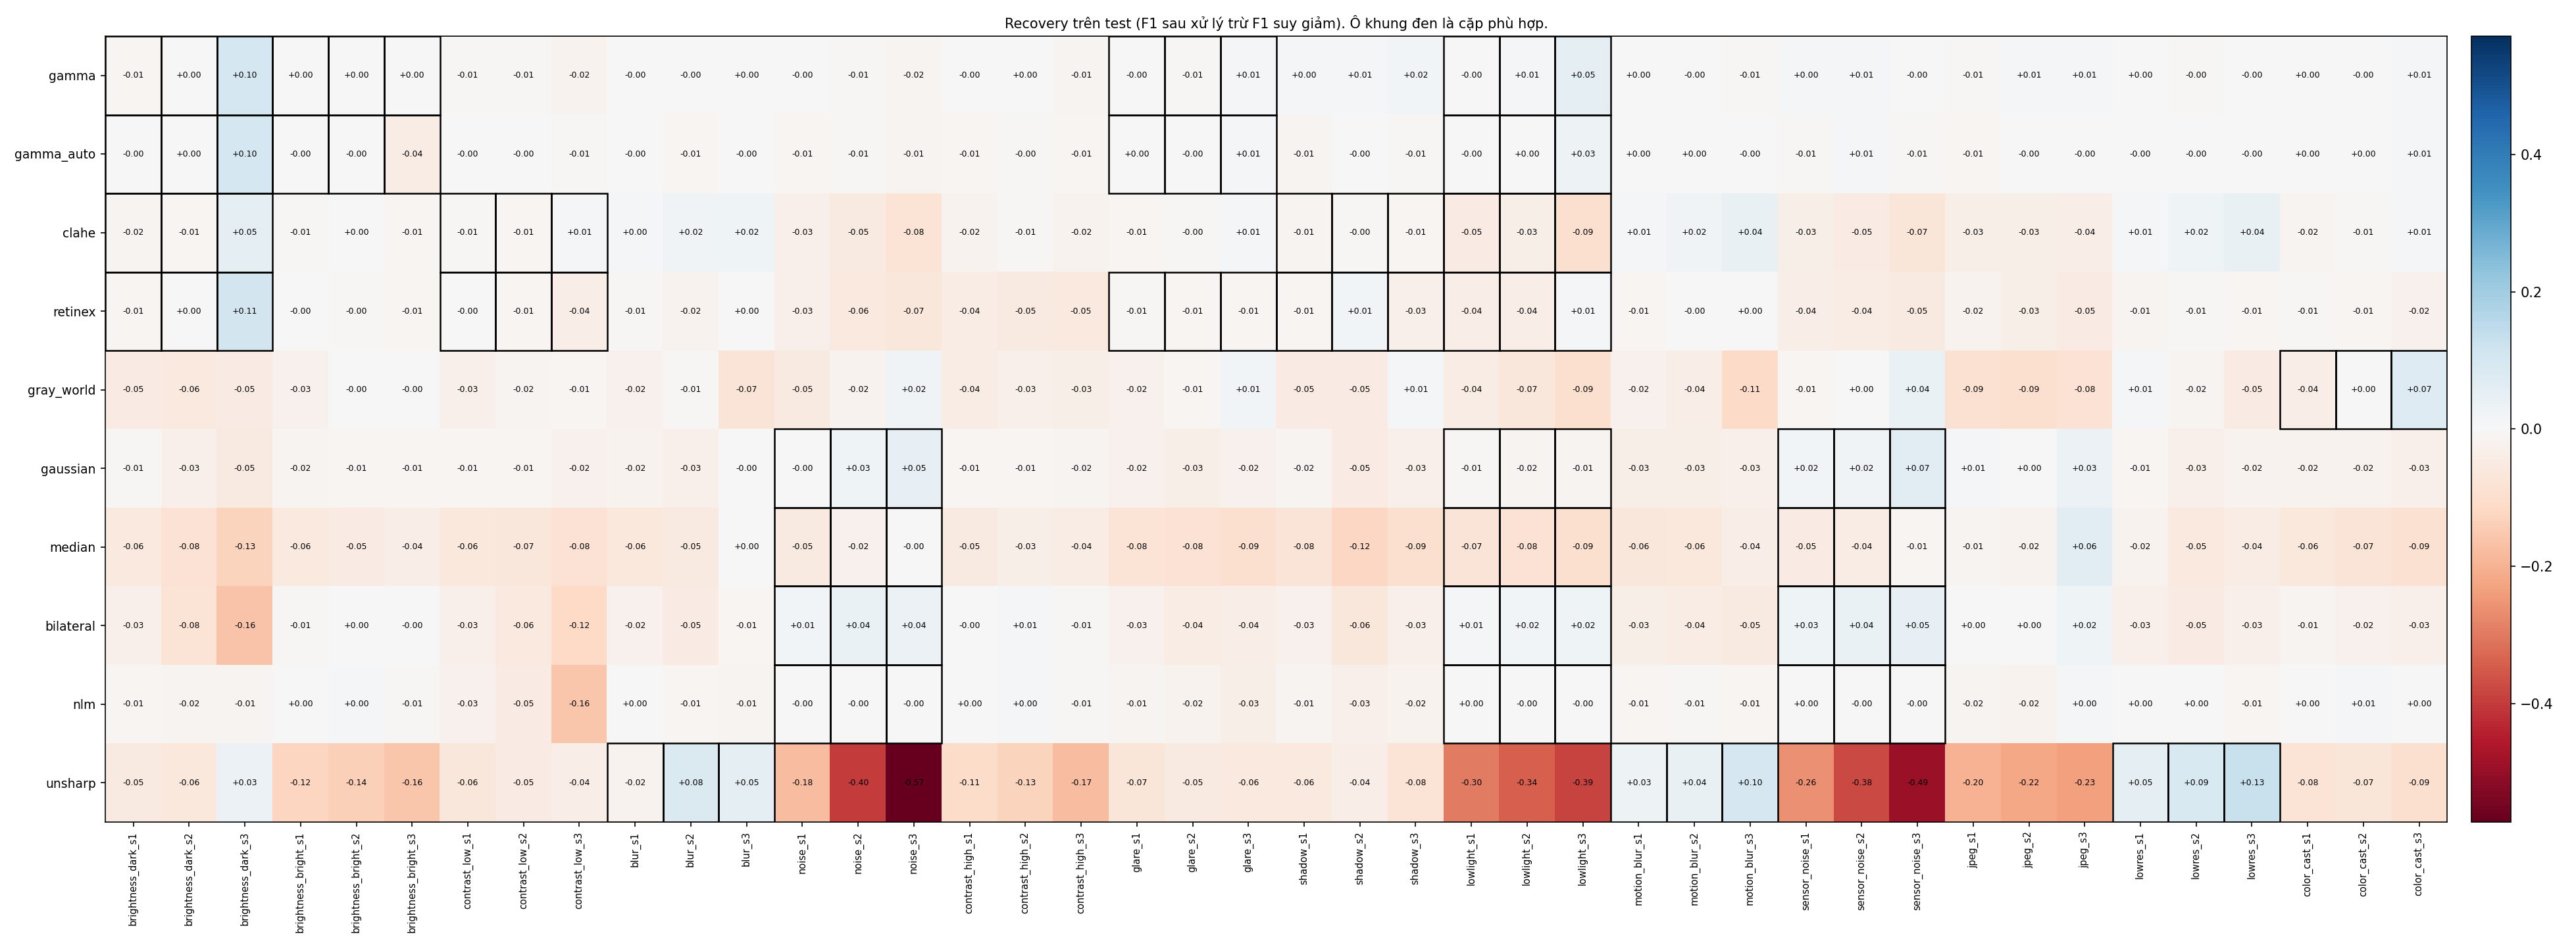

normalized_recovery_heatmap


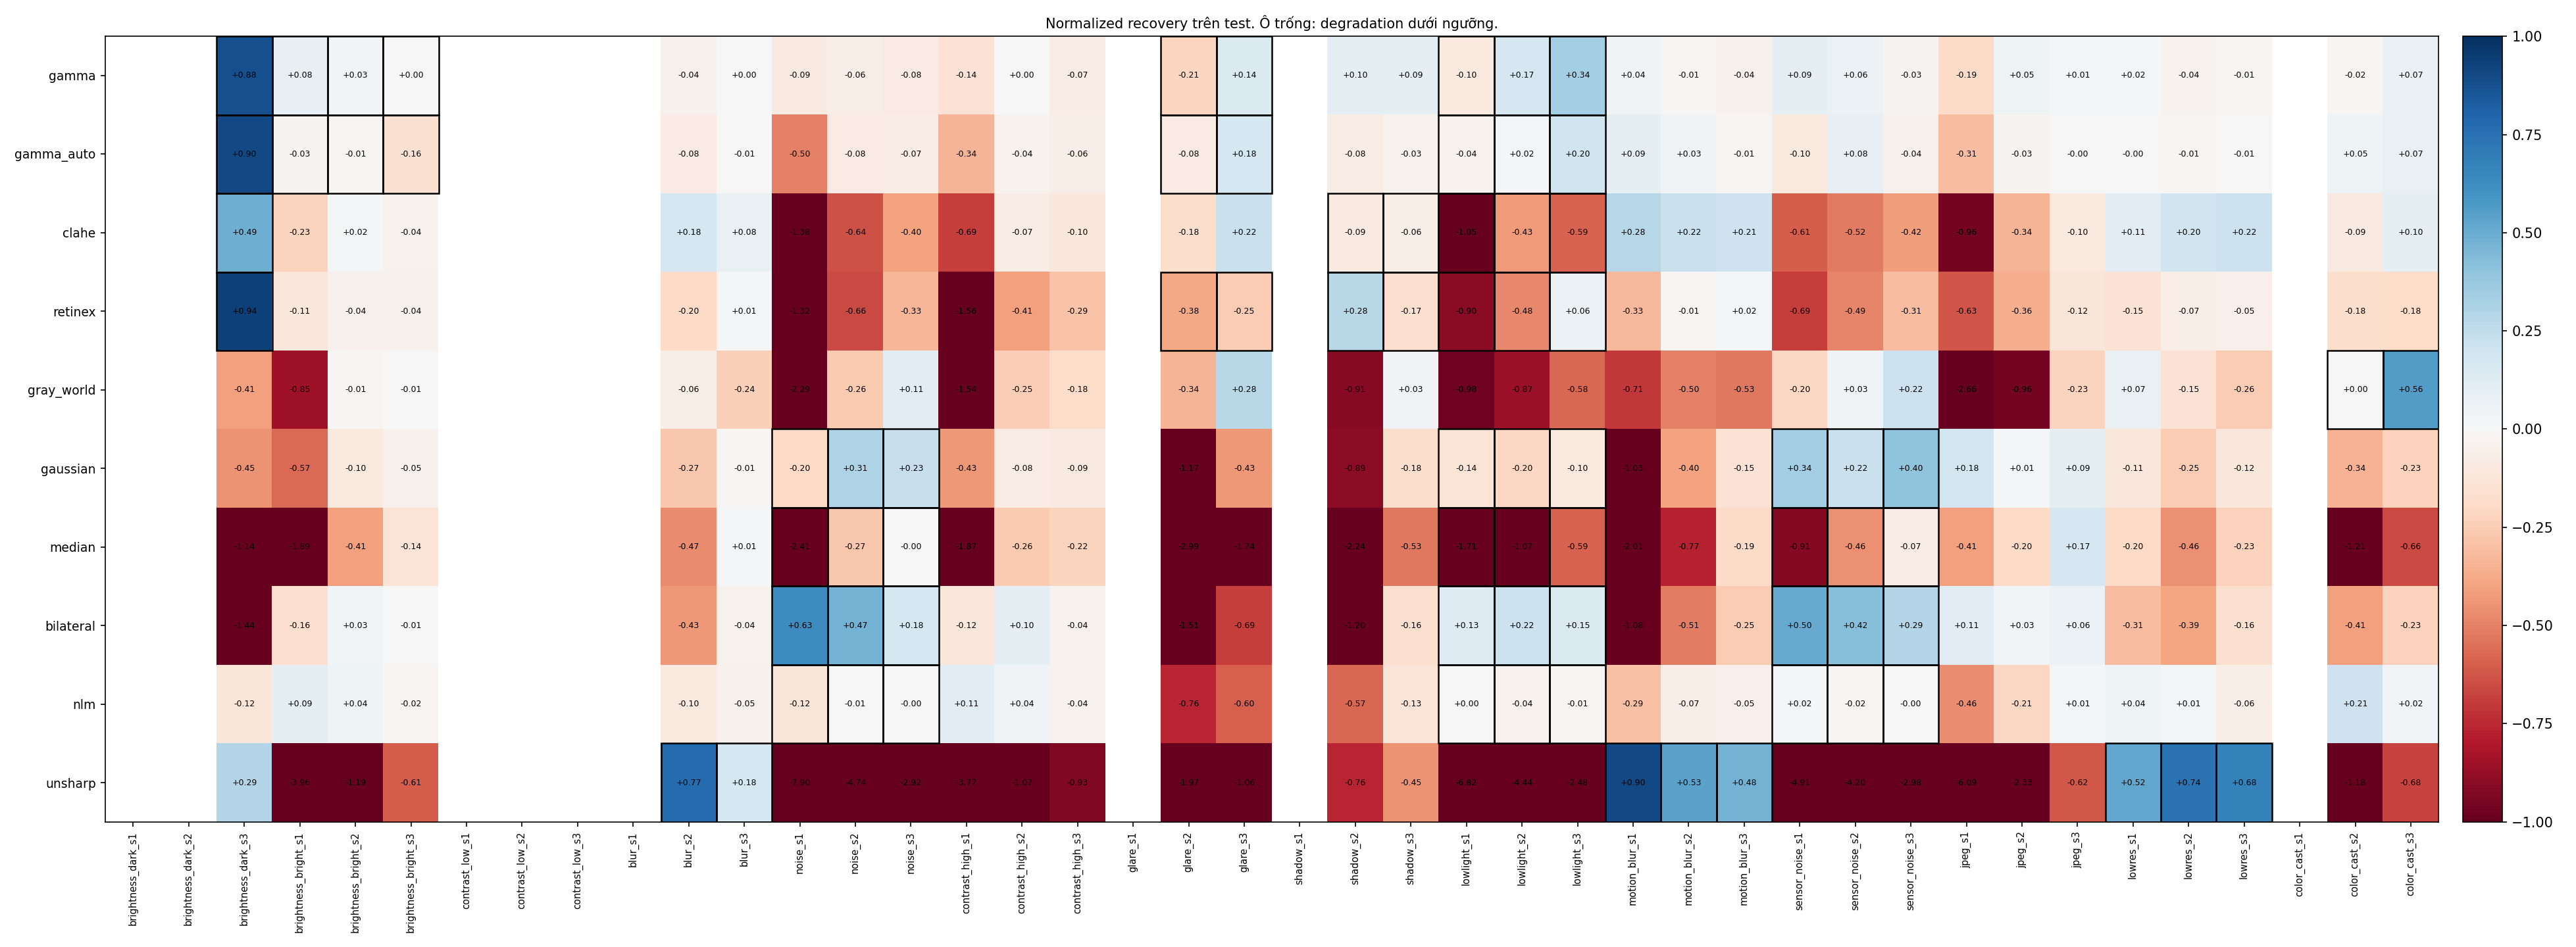

strategies_by_family


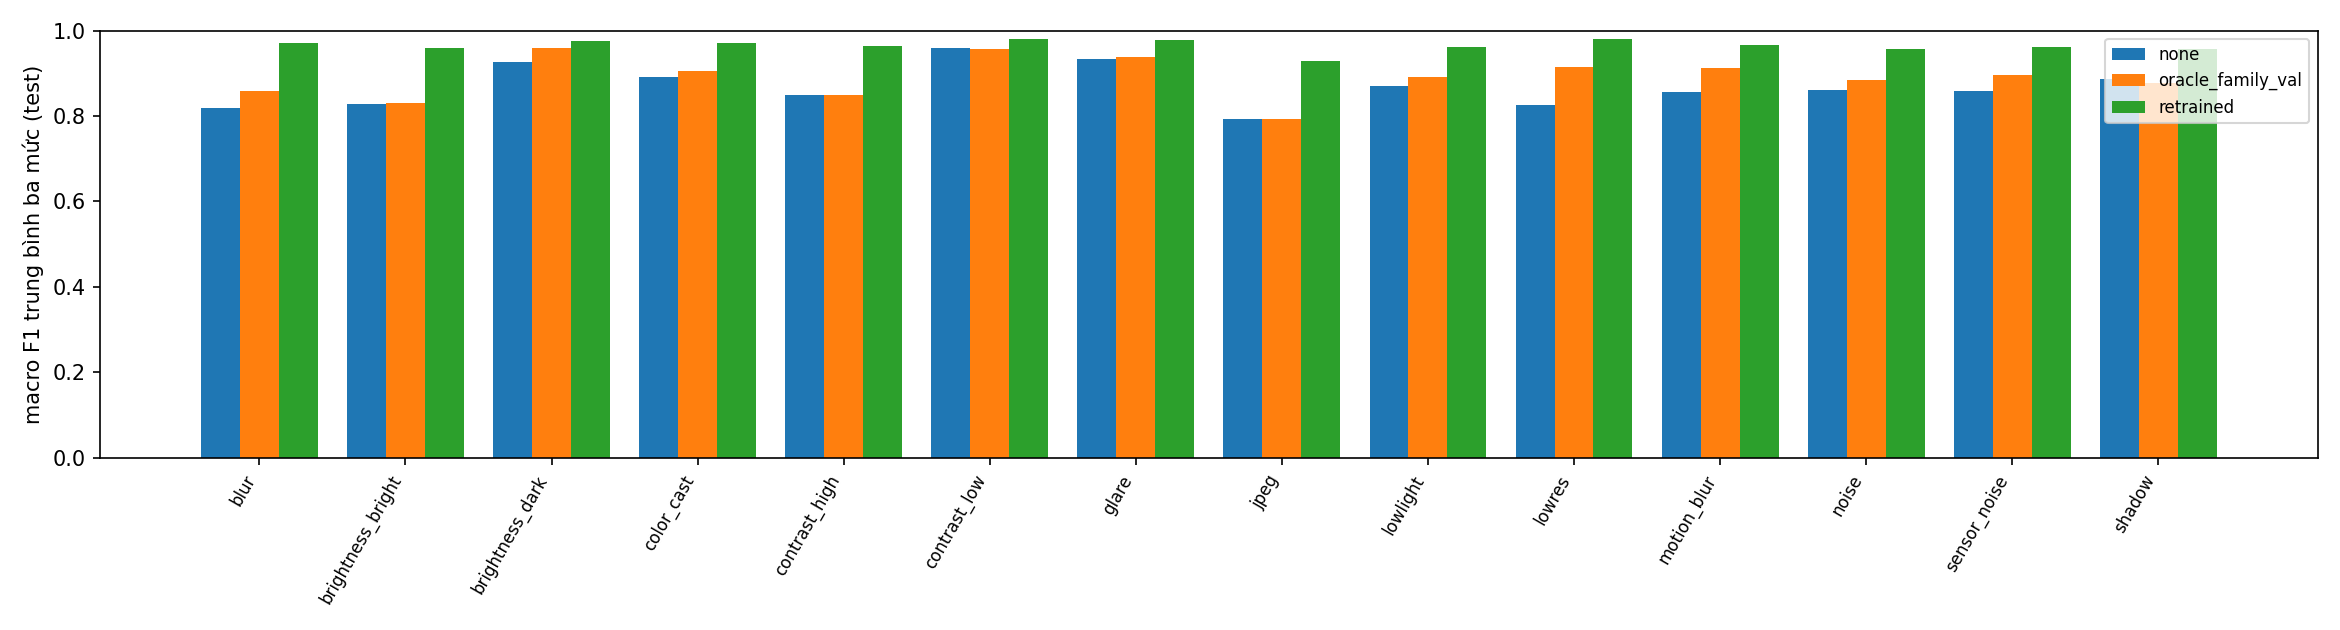

In [7]:
for name in ["recovery_heatmap", "normalized_recovery_heatmap", "strategies_by_family"]:
    print(name)
    display(Image(filename=str(REP / f"{name}.png")))

## 5. Lưu kết quả

Nén toàn bộ thư mục kết quả. Bản chốt nằm ở `reports/recovery_map/` (bảng CSV, JSON tóm tắt, hình). File dự đoán từng ảnh (`recovery_predictions_test.npz`) nằm trong output Kaggle.

In [8]:
import zipfile

archive = Path("/kaggle/working/recovery_map_outputs.zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as bundle:
    for folder in (RES, REP):
        for path in sorted(folder.rglob("*")):
            if path.is_file():
                bundle.write(path, path.relative_to(REPO_DIR).as_posix())
print(f"Đã nén {archive} ({archive.stat().st_size / 1024**2:.1f} MB)")
print("Bản chốt: reports/recovery_map/. Dự đoán từng ảnh: outputs/results/recovery_map/recovery_predictions_test.npz")

Đã nén /kaggle/working/recovery_map_outputs.zip (4.8 MB)
Bản chốt: reports/recovery_map/. Dự đoán từng ảnh: outputs/results/recovery_map/recovery_predictions_test.npz
